# Online Retail Transactions — Starter Notebook
**Applied Statistics and Data Science I · EN.553.413/613**

**Source:** [UCI Machine Learning Repository — Online Retail](https://archive.ics.uci.edu/dataset/352/online-retail)

Every transaction from a UK-based online gift retailer between 1 Dec 2010 and 9 Dec 2011. Many of its customers are wholesalers. Each row is one **line item**: one product on one invoice.

| Column | Description (from UCI) |
|---|---|
| `InvoiceNo` | 6-digit invoice number; a code starting with `C` indicates a cancellation |
| `StockCode` | Product code |
| `Description` | Product name |
| `Quantity` | Quantity of the product on this invoice line |
| `InvoiceDate` | Date and time of the invoice |
| `UnitPrice` | Price per unit, in pounds sterling (£) |
| `CustomerID` | 5-digit customer number |
| `Country` | Country where the customer resides |

This notebook only loads the data and makes a few basic plots. The analysis is up to you.

> The first run downloads the data (internet required, about 23 MB) and saves it in a local `data/` folder. Reading the Excel file takes a minute or two.

## 1. Load the data

In [1]:
from pathlib import Path
import io, zipfile
import pandas as pd
import matplotlib.pyplot as plt
import requests

DATA = Path('data')
DATA.mkdir(exist_ok=True)
ZIP_PATH = DATA / 'online_retail_uci352.zip'
URL = 'https://archive.ics.uci.edu/static/public/352/online+retail.zip'

if not ZIP_PATH.is_file():
    r = requests.get(URL, timeout=300)
    r.raise_for_status()
    ZIP_PATH.write_bytes(r.content)

with zipfile.ZipFile(ZIP_PATH) as z:
    df = pd.read_excel(io.BytesIO(z.read('Online Retail.xlsx')),
                       dtype={'InvoiceNo': str, 'StockCode': str})

print(df.shape)
df.head()

(541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [2]:
df.describe(include='all').T

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
InvoiceNo,541909,25900,573585,1114,NaN,NaN,NaN,NaN,NaN,NaN,NaN
StockCode,541909,4070,85123A,2313,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Description,540455,4223,WHITE HANGING HEART T-LIGHT HOLDER,2369,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,541909.0,NaN,NaN,NaN,9.55225,-80995.0,1.0,3.0,10.0,80995.0,218.081158
InvoiceDate,541909,NaN,NaN,NaN,2011-07-04 13:34:57.156386048,2010-12-01 08:26:00,2011-03-28 11:34:00,2011-07-19 17:17:00,2011-10-19 11:27:00,2011-12-09 12:50:00,NaN
UnitPrice,541909.0,NaN,NaN,NaN,4.611114,-11062.06,1.25,2.08,4.13,38970.0,96.759853
CustomerID,406829.0,NaN,NaN,NaN,15287.69057,12346.0,13953.0,15152.0,16791.0,18287.0,1713.600303
Country,541909,38,United Kingdom,495478,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 2. A first look

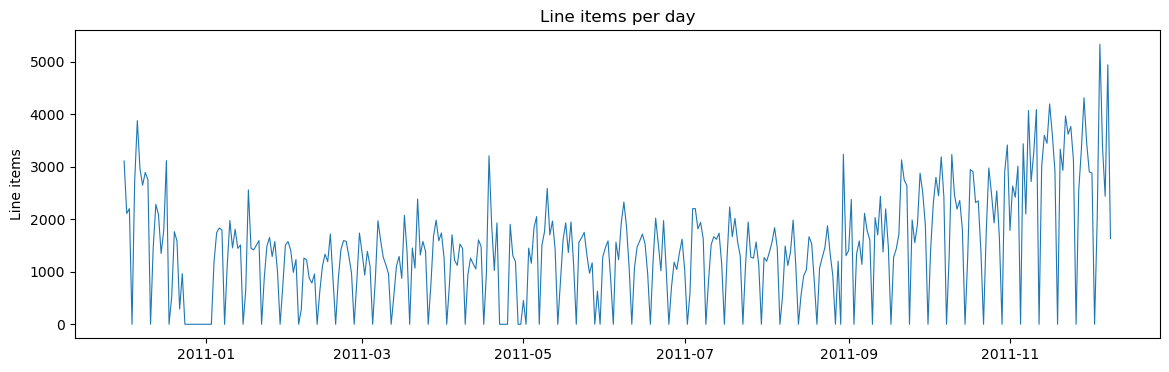

In [3]:
daily = df.set_index('InvoiceDate').resample('D').size()
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(daily.index, daily.values, lw=0.8)
ax.set(ylabel='Line items', title='Line items per day')
plt.show()

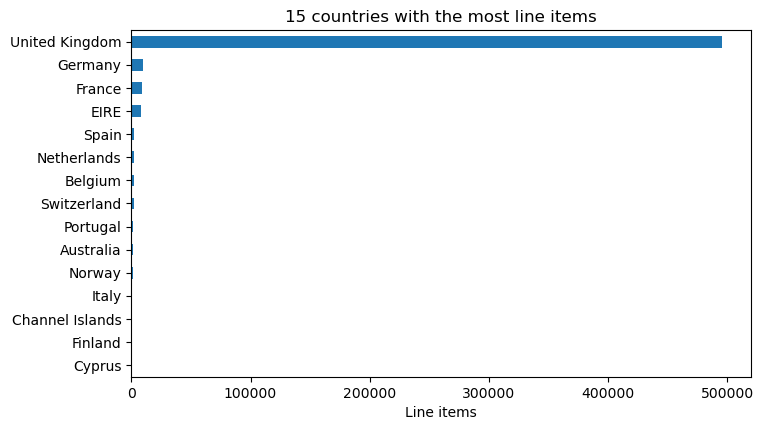

In [4]:
fig, ax = plt.subplots(figsize=(8, 4.5))
df['Country'].value_counts().head(15).sort_values().plot.barh(ax=ax)
ax.set(xlabel='Line items', ylabel='', title='15 countries with the most line items')
plt.show()

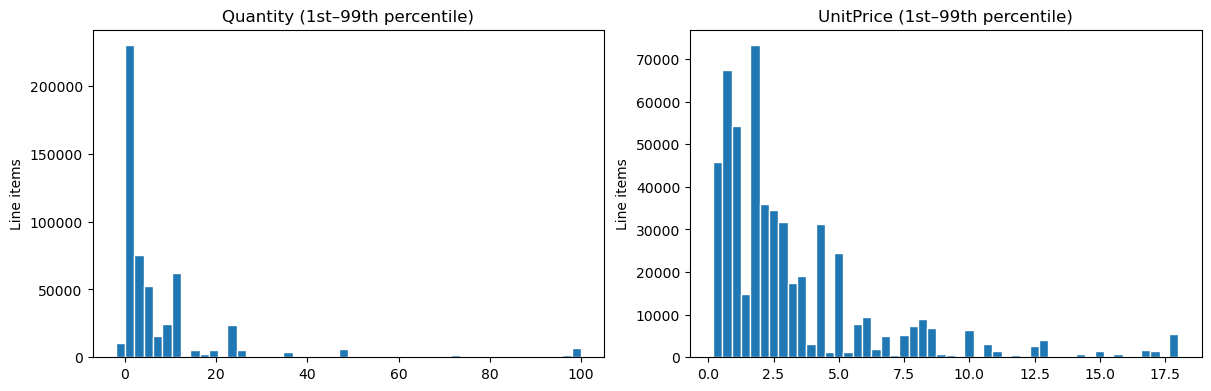

In [5]:
# Both variables have very long tails, so these histograms show only the middle 98% of values.
fig, axs = plt.subplots(1, 2, figsize=(12, 3.8), constrained_layout=True)
for ax, col in zip(axs, ['Quantity', 'UnitPrice']):
    lo, hi = df[col].quantile([0.01, 0.99])
    ax.hist(df[col].clip(lo, hi), bins=50, range=(lo, hi), edgecolor='white')
    ax.set(title=f'{col} (1st–99th percentile)', ylabel='Line items')
plt.show()

## 3. Your exploration
Add your own analysis below.